# 🔬 Analisis Uji Impak Material Fe A36 & Al 1XXX
## Machine Learning untuk Prediksi Energi Impak & Shear Fracture

**Tujuan**: Membangun model prediksi menggunakan Machine Learning untuk:
1. Prediksi Energi Impak (E, Joule) berdasarkan suhu dan dimensi spesimen
2. Prediksi % Shear Fracture berdasarkan suhu dan dimensi spesimen

**Dataset**: Hasil uji impak (Charpy/Izod) pada 54 spesimen
- Fe A36 (Baja Struktural): 27 sampel
- Al 1XXX (Aluminium Seri 1000): 27 sampel

---
# PHASE 1: Exploratory Data Analysis (EDA)
---

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi Visualisasi
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_style('whitegrid')
sns.set_palette('deep')

print("✅ Libraries berhasil diimport!")

✅ Libraries berhasil diimport!


In [2]:
# Load Dataset
df = pd.read_csv('../data/raw/impact_test_dataset_fe_a36_al_1xxx.csv')

# Rename kolom agar lebih mudah digunakan
df.columns = ['Material', 'T_C', 'a_mm', 'b_mm', 'Luas_A_mm2', 'E_Joule', 'Shear_Fracture_pct']

print(f"📊 Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"📋 Kolom: {list(df.columns)}")
df.head(10)

📊 Dataset berhasil dimuat: 53 baris, 7 kolom
📋 Kolom: ['Material', 'T_C', 'a_mm', 'b_mm', 'Luas_A_mm2', 'E_Joule', 'Shear_Fracture_pct']


,Material,T_C,a_mm,b_mm,Luas_A_mm2,E_Joule,Shear_Fracture_pct
0,Fe A36,-4.5,8.53,10.05,85.73,70,21
1,Fe A36,27.2,9.98,10.10,100.80,122,65
2,Fe A36,189.0,9.23,9.96,91.93,132,40
3,Fe A36,-12.3,8.34,10.02,83.57,18,5
4,Fe A36,28.0,9.30,10.10,93.93,152,62
5,Fe A36,26.1,8.75,9.93,86.89,123,74
6,Fe A36,-17.5,8.78,10.16,89.20,43,30
7,Fe A36,125.0,10.00,9.94,99.40,152,50
8,Fe A36,208.0,8.68,11.17,96.96,143,30
9,Fe A36,176.0,9.10,9.86,89.73,142,60


## 1.1 Statistik Deskriptif

In [3]:
# Statistik Deskriptif Keseluruhan
print("=" * 60)
print("📊 STATISTIK DESKRIPTIF KESELURUHAN")
print("=" * 60)
df.describe().round(2)

📊 STATISTIK DESKRIPTIF KESELURUHAN


,T_C,a_mm,b_mm,Luas_A_mm2,E_Joule,Shear_Fracture_pct
count,53.00,53.00,53.00,53.00,53.00,53.00
mean,50.74,8.83,9.92,87.72,85.13,44.96
std,70.39,0.70,0.45,8.69,46.57,29.75
min,-29.00,5.88,7.62,44.81,9.00,0.00
25%,-4.50,8.56,9.85,84.59,51.00,20.00
50%,27.60,8.76,10.00,87.44,82.00,48.00
75%,124.90,9.10,10.04,91.93,126.00,70.00
max,208.00,10.06,11.18,101.00,194.00,92.00


In [4]:
# Statistik Deskriptif per Material
print("=" * 60)
print("📊 STATISTIK DESKRIPTIF PER MATERIAL")
print("=" * 60)

for material in df['Material'].unique():
    print(f"\n{'─' * 40}")
    print(f"🔩 {material}")
    print(f"{'─' * 40}")
    subset = df[df['Material'] == material]
    print(f"  Jumlah sampel  : {len(subset)}")
    print(f"  Rentang Suhu   : {subset['T_C'].min():.1f}°C s/d {subset['T_C'].max():.1f}°C")
    print(f"  Energi (E)     : Mean={subset['E_Joule'].mean():.1f} J, Std={subset['E_Joule'].std():.1f} J")
    print(f"  Shear Fracture : Mean={subset['Shear_Fracture_pct'].mean():.1f}%, Std={subset['Shear_Fracture_pct'].std():.1f}%")

📊 STATISTIK DESKRIPTIF PER MATERIAL

────────────────────────────────────────
🔩 Fe A36
────────────────────────────────────────
  Jumlah sampel  : 26
  Rentang Suhu   : -22.2°C s/d 208.0°C
  Energi (E)     : Mean=100.0 J, Std=57.5 J
  Shear Fracture : Mean=36.5%, Std=24.5%

────────────────────────────────────────
🔩 Al 1XXX
────────────────────────────────────────
  Jumlah sampel  : 27
  Rentang Suhu   : -29.0°C s/d 189.6°C
  Energi (E)     : Mean=70.8 J, Std=27.0 J
  Shear Fracture : Mean=53.1%, Std=32.5%


In [5]:
# Cek Missing Values & Data Types
print("=" * 60)
print("📋 INFO DATASET")
print("=" * 60)
print(f"\n🔍 Missing Values:")
print(df.isnull().sum())
print(f"\n📊 Tipe Data:")
print(df.dtypes)
print(f"\n📏 Duplikasi: {df.duplicated().sum()} baris duplikat")

📋 INFO DATASET

🔍 Missing Values:
Material              0
T_C                   0
a_mm                  0
b_mm                  0
Luas_A_mm2            0
E_Joule               0
Shear_Fracture_pct    0
dtype: int64

📊 Tipe Data:
Material                  str
T_C                   float64
a_mm                  float64
b_mm                  float64
Luas_A_mm2            float64
E_Joule                 int64
Shear_Fracture_pct      int64
dtype: object

📏 Duplikasi: 0 baris duplikat


## 1.2 Feature Engineering

In [6]:
# Feature Engineering
# 1. Ketangguhan (Impact Toughness) = E / A → kJ/m²
df['Ketangguhan_kJ_m2'] = (df['E_Joule'] / df['Luas_A_mm2']) * 1000  # konversi ke kJ/m²

# 2. Kategorisasi Suhu
def kategorisasi_suhu(t):
    if t < 0:
        return 'Dingin (< 0°C)'
    elif t <= 50:
        return 'Ruangan (0-50°C)'
    else:
        return 'Panas (> 50°C)'

df['Kategori_Suhu'] = df['T_C'].apply(kategorisasi_suhu)

# 3. Rasio dimensi
df['Rasio_ab'] = df['a_mm'] / df['b_mm']

# 4. Material encoding (untuk korelasi)
df['Material_encoded'] = (df['Material'] == 'Fe A36').astype(int)

print("✅ Feature Engineering selesai!")
print(f"Kolom baru: Ketangguhan_kJ_m2, Kategori_Suhu, Rasio_ab, Material_encoded")
print(f"\n📊 Dataset sekarang: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

✅ Feature Engineering selesai!
Kolom baru: Ketangguhan_kJ_m2, Kategori_Suhu, Rasio_ab, Material_encoded

📊 Dataset sekarang: 53 baris, 11 kolom


,Material,T_C,a_mm,b_mm,Luas_A_mm2,E_Joule,Shear_Fracture_pct,Ketangguhan_kJ_m2,Kategori_Suhu,Rasio_ab,Material_encoded
0,Fe A36,-4.5,8.53,10.05,85.73,70,21,816.516972,Dingin (< 0°C),0.848756,1
1,Fe A36,27.2,9.98,10.10,100.80,122,65,1210.317460,Ruangan (0-50°C),0.988119,1
2,Fe A36,189.0,9.23,9.96,91.93,132,40,1435.875122,Panas (> 50°C),0.926707,1
3,Fe A36,-12.3,8.34,10.02,83.57,18,5,215.388297,Dingin (< 0°C),0.832335,1
4,Fe A36,28.0,9.30,10.10,93.93,152,62,1618.226339,Ruangan (0-50°C),0.920792,1


## 1.3 Visualisasi Distribusi Data

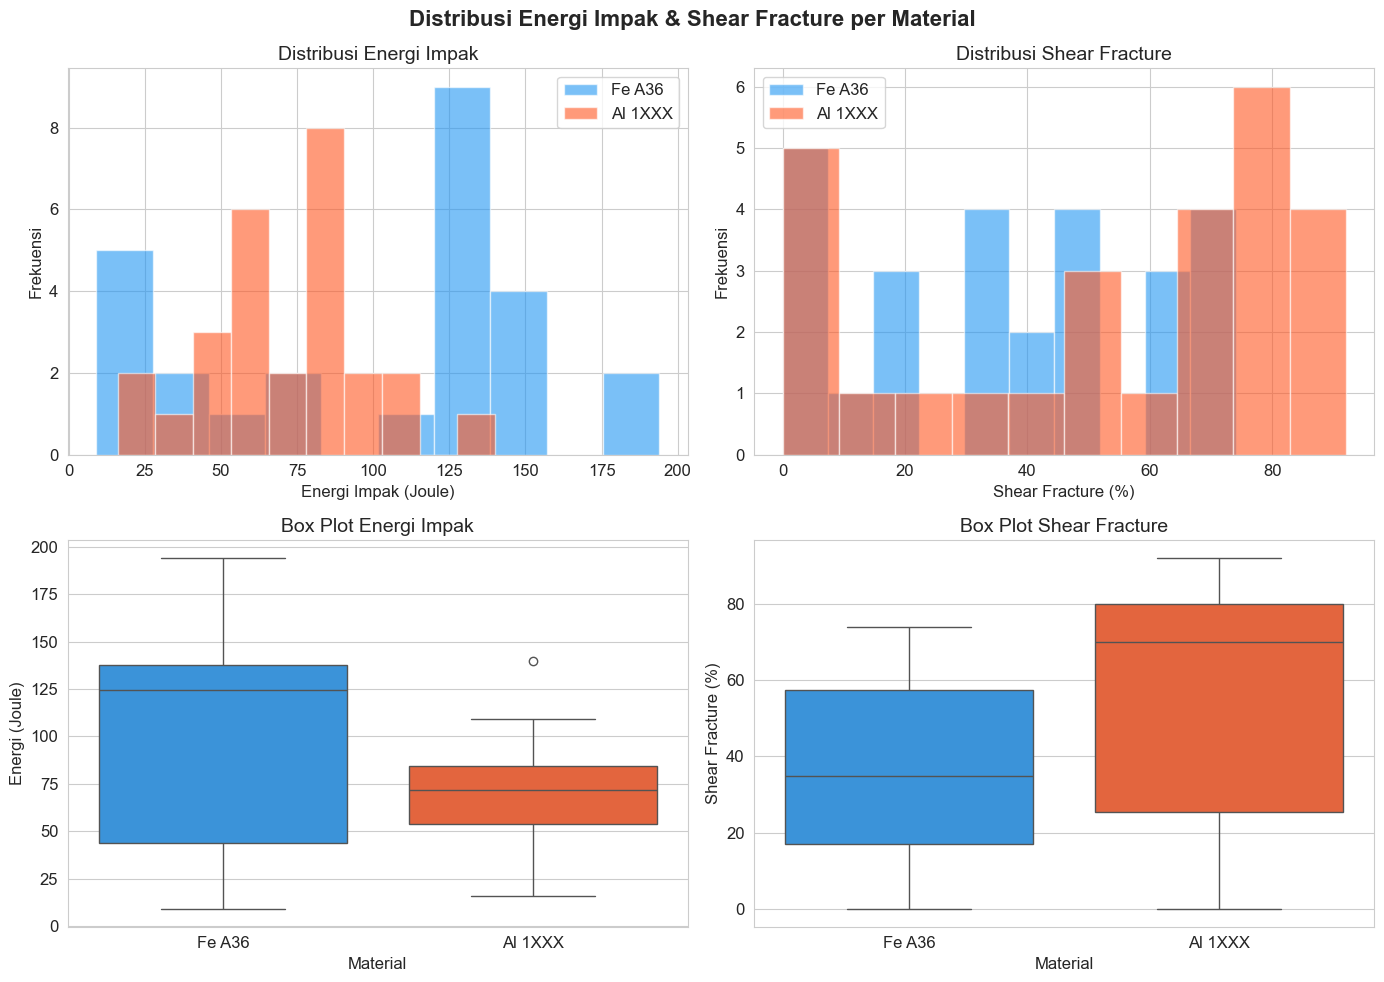

💾 Grafik disimpan: output/01_data_distribution.png


In [7]:
# Distribusi Energi dan Shear Fracture per Material
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribusi Energi Impak & Shear Fracture per Material', fontsize=16, fontweight='bold')

# Histogram E per material
for material, color in zip(df['Material'].unique(), ['#2196F3', '#FF5722']):
    subset = df[df['Material'] == material]
    axes[0, 0].hist(subset['E_Joule'], bins=10, alpha=0.6, label=material, color=color, edgecolor='white')
axes[0, 0].set_xlabel('Energi Impak (Joule)')
axes[0, 0].set_ylabel('Frekuensi')
axes[0, 0].set_title('Distribusi Energi Impak')
axes[0, 0].legend()

# Histogram Shear Fracture per material
for material, color in zip(df['Material'].unique(), ['#2196F3', '#FF5722']):
    subset = df[df['Material'] == material]
    axes[0, 1].hist(subset['Shear_Fracture_pct'], bins=10, alpha=0.6, label=material, color=color, edgecolor='white')
axes[0, 1].set_xlabel('Shear Fracture (%)')
axes[0, 1].set_ylabel('Frekuensi')
axes[0, 1].set_title('Distribusi Shear Fracture')
axes[0, 1].legend()

# Box plot E per material
sns.boxplot(data=df, x='Material', y='E_Joule', ax=axes[1, 0], palette=['#2196F3', '#FF5722'])
axes[1, 0].set_title('Box Plot Energi Impak')
axes[1, 0].set_ylabel('Energi (Joule)')

# Box plot Shear Fracture per material
sns.boxplot(data=df, x='Material', y='Shear_Fracture_pct', ax=axes[1, 1], palette=['#2196F3', '#FF5722'])
axes[1, 1].set_title('Box Plot Shear Fracture')
axes[1, 1].set_ylabel('Shear Fracture (%)')

plt.tight_layout()
plt.savefig('../outputs/figures/01_data_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/01_data_distribution.png")

## 1.4 Scatter Plot: Suhu vs Performa Impak

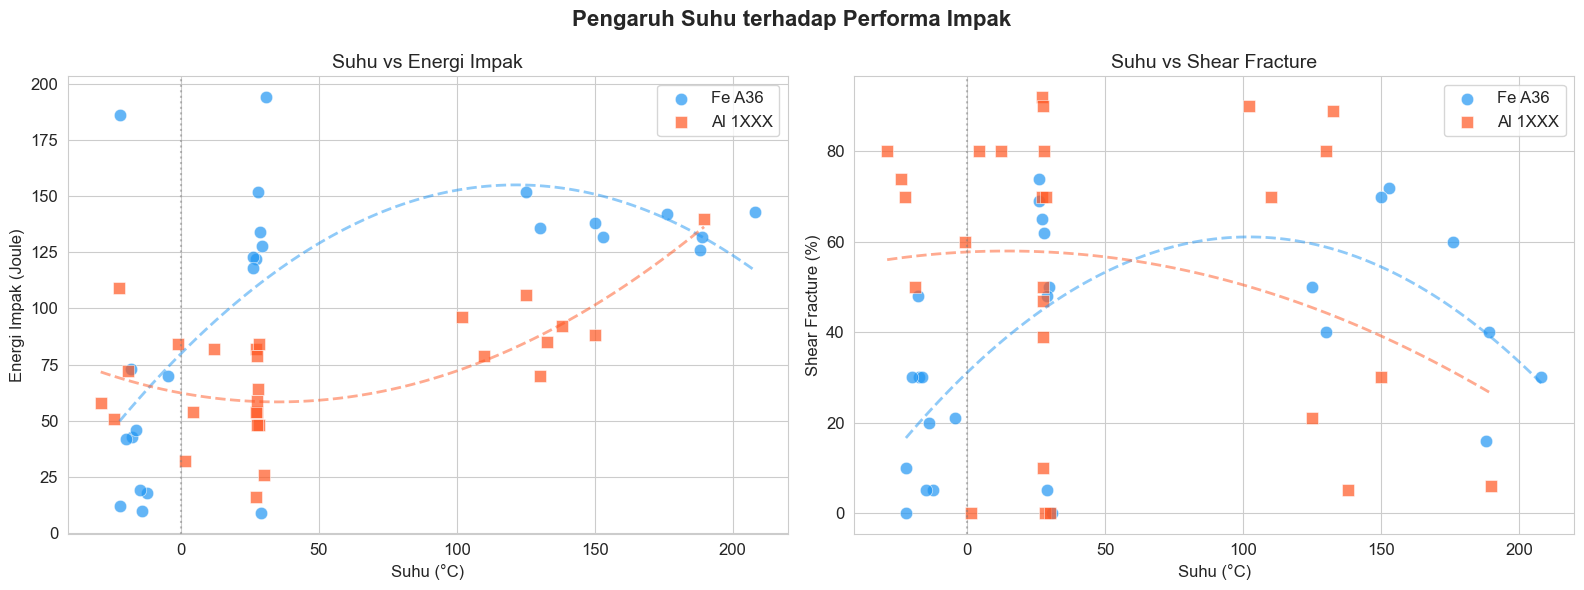

💾 Grafik disimpan: output/02_temperature_vs_performance.png


In [8]:
# Scatter Plot: Suhu vs Energi & Suhu vs Shear Fracture
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Pengaruh Suhu terhadap Performa Impak', fontsize=16, fontweight='bold')

colors = {'Fe A36': '#2196F3', 'Al 1XXX': '#FF5722'}
markers = {'Fe A36': 'o', 'Al 1XXX': 's'}

for material in df['Material'].unique():
    subset = df[df['Material'] == material]
    
    # Suhu vs Energi
    axes[0].scatter(subset['T_C'], subset['E_Joule'], 
                    c=colors[material], marker=markers[material],
                    s=80, alpha=0.7, label=material, edgecolors='white', linewidth=0.5)
    # Trendline
    z = np.polyfit(subset['T_C'], subset['E_Joule'], 2)
    p = np.poly1d(z)
    x_trend = np.linspace(subset['T_C'].min(), subset['T_C'].max(), 100)
    axes[0].plot(x_trend, p(x_trend), '--', color=colors[material], alpha=0.5, linewidth=2)
    
    # Suhu vs Shear Fracture
    axes[1].scatter(subset['T_C'], subset['Shear_Fracture_pct'], 
                    c=colors[material], marker=markers[material],
                    s=80, alpha=0.7, label=material, edgecolors='white', linewidth=0.5)
    z2 = np.polyfit(subset['T_C'], subset['Shear_Fracture_pct'], 2)
    p2 = np.poly1d(z2)
    axes[1].plot(x_trend, p2(x_trend), '--', color=colors[material], alpha=0.5, linewidth=2)

axes[0].set_xlabel('Suhu (°C)')
axes[0].set_ylabel('Energi Impak (Joule)')
axes[0].set_title('Suhu vs Energi Impak')
axes[0].legend()
axes[0].axvline(x=0, color='gray', linestyle=':', alpha=0.5)

axes[1].set_xlabel('Suhu (°C)')
axes[1].set_ylabel('Shear Fracture (%)')
axes[1].set_title('Suhu vs Shear Fracture')
axes[1].legend()
axes[1].axvline(x=0, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('../outputs/figures/02_temperature_vs_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/02_temperature_vs_performance.png")

## 1.5 Heatmap Korelasi

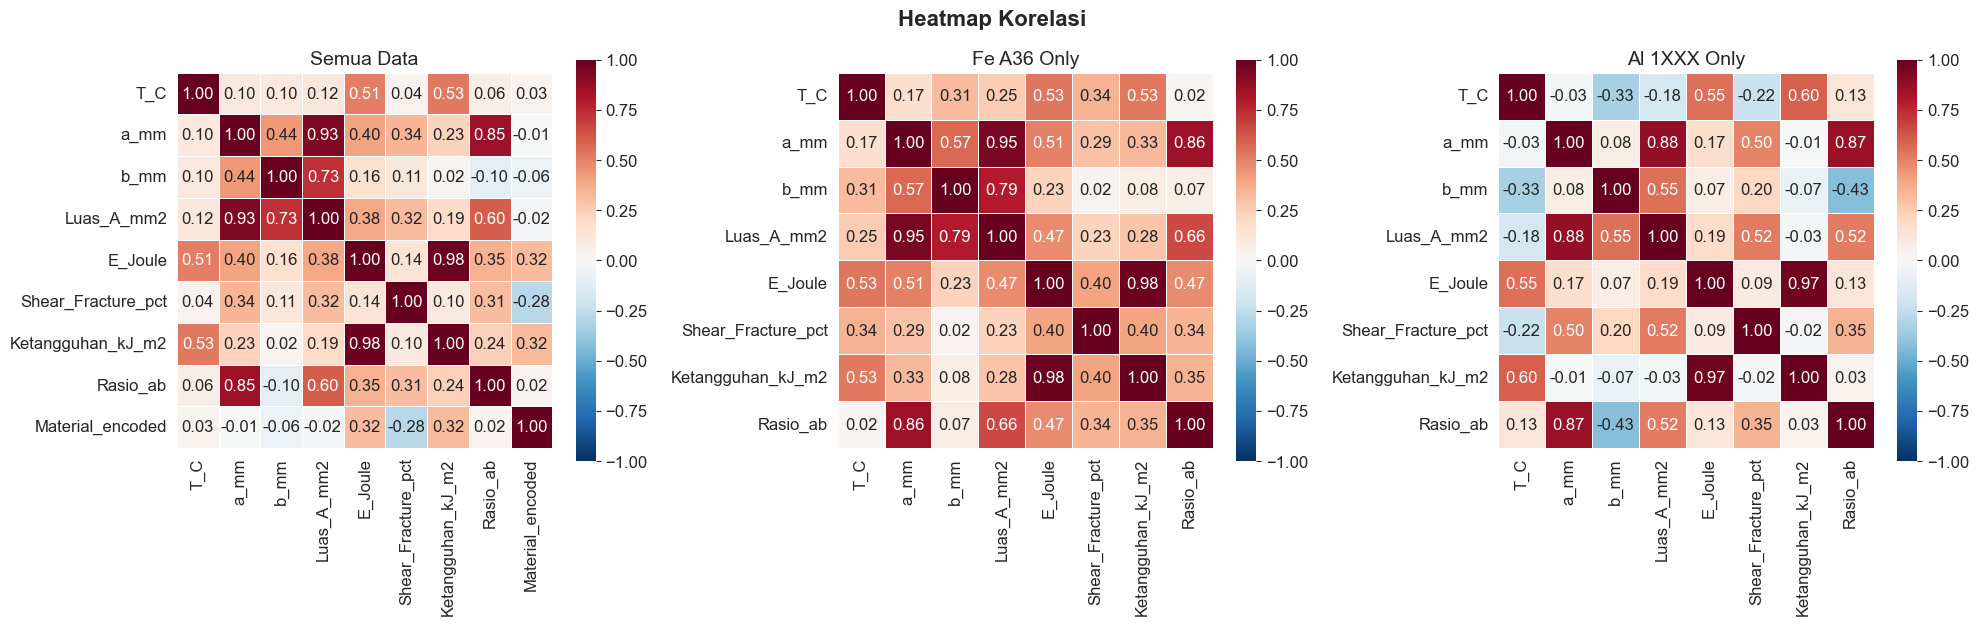

💾 Grafik disimpan: output/03_correlation_heatmap.png


In [9]:
# Heatmap Korelasi
numerical_cols = ['T_C', 'a_mm', 'b_mm', 'Luas_A_mm2', 'E_Joule', 'Shear_Fracture_pct', 
                  'Ketangguhan_kJ_m2', 'Rasio_ab', 'Material_encoded']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Heatmap Korelasi', fontsize=16, fontweight='bold')

# Korelasi keseluruhan
corr_all = df[numerical_cols].corr()
sns.heatmap(corr_all, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=axes[0], square=True, linewidths=0.5, vmin=-1, vmax=1)
axes[0].set_title('Semua Data')

# Korelasi Fe A36
corr_fe = df[df['Material'] == 'Fe A36'][numerical_cols[:-1]].corr()
sns.heatmap(corr_fe, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=axes[1], square=True, linewidths=0.5, vmin=-1, vmax=1)
axes[1].set_title('Fe A36 Only')

# Korelasi Al 1XXX
corr_al = df[df['Material'] == 'Al 1XXX'][numerical_cols[:-1]].corr()
sns.heatmap(corr_al, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=axes[2], square=True, linewidths=0.5, vmin=-1, vmax=1)
axes[2].set_title('Al 1XXX Only')

plt.tight_layout()
plt.savefig('../outputs/figures/03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/03_correlation_heatmap.png")

## 1.6 Analisis per Kategori Suhu

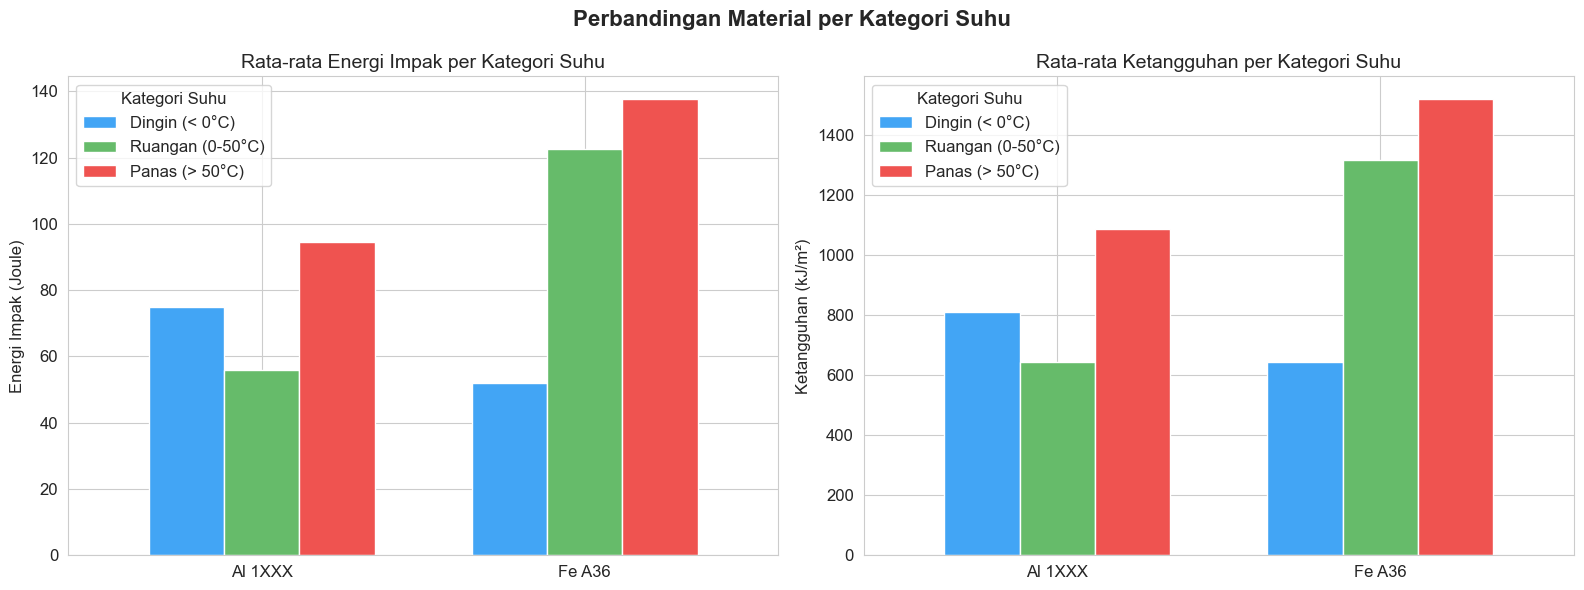

💾 Grafik disimpan: output/04_temperature_category_comparison.png


In [10]:
# Perbandingan per Kategori Suhu
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Perbandingan Material per Kategori Suhu', fontsize=16, fontweight='bold')

# Grouped bar: rata-rata Energi per Material & Kategori Suhu
suhu_order = ['Dingin (< 0°C)', 'Ruangan (0-50°C)', 'Panas (> 50°C)']
grouped_E = df.groupby(['Material', 'Kategori_Suhu'])['E_Joule'].mean().unstack()
grouped_E = grouped_E[suhu_order]
grouped_E.plot(kind='bar', ax=axes[0], color=['#42A5F5', '#66BB6A', '#EF5350'], edgecolor='white', width=0.7)
axes[0].set_title('Rata-rata Energi Impak per Kategori Suhu')
axes[0].set_ylabel('Energi Impak (Joule)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Kategori Suhu')

# Grouped bar: rata-rata Ketangguhan per Material & Kategori Suhu
grouped_K = df.groupby(['Material', 'Kategori_Suhu'])['Ketangguhan_kJ_m2'].mean().unstack()
grouped_K = grouped_K[suhu_order]
grouped_K.plot(kind='bar', ax=axes[1], color=['#42A5F5', '#66BB6A', '#EF5350'], edgecolor='white', width=0.7)
axes[1].set_title('Rata-rata Ketangguhan per Kategori Suhu')
axes[1].set_ylabel('Ketangguhan (kJ/m²)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Kategori Suhu')

plt.tight_layout()
plt.savefig('../outputs/figures/04_temperature_category_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/04_temperature_category_comparison.png")

## 1.7 Pair Plot

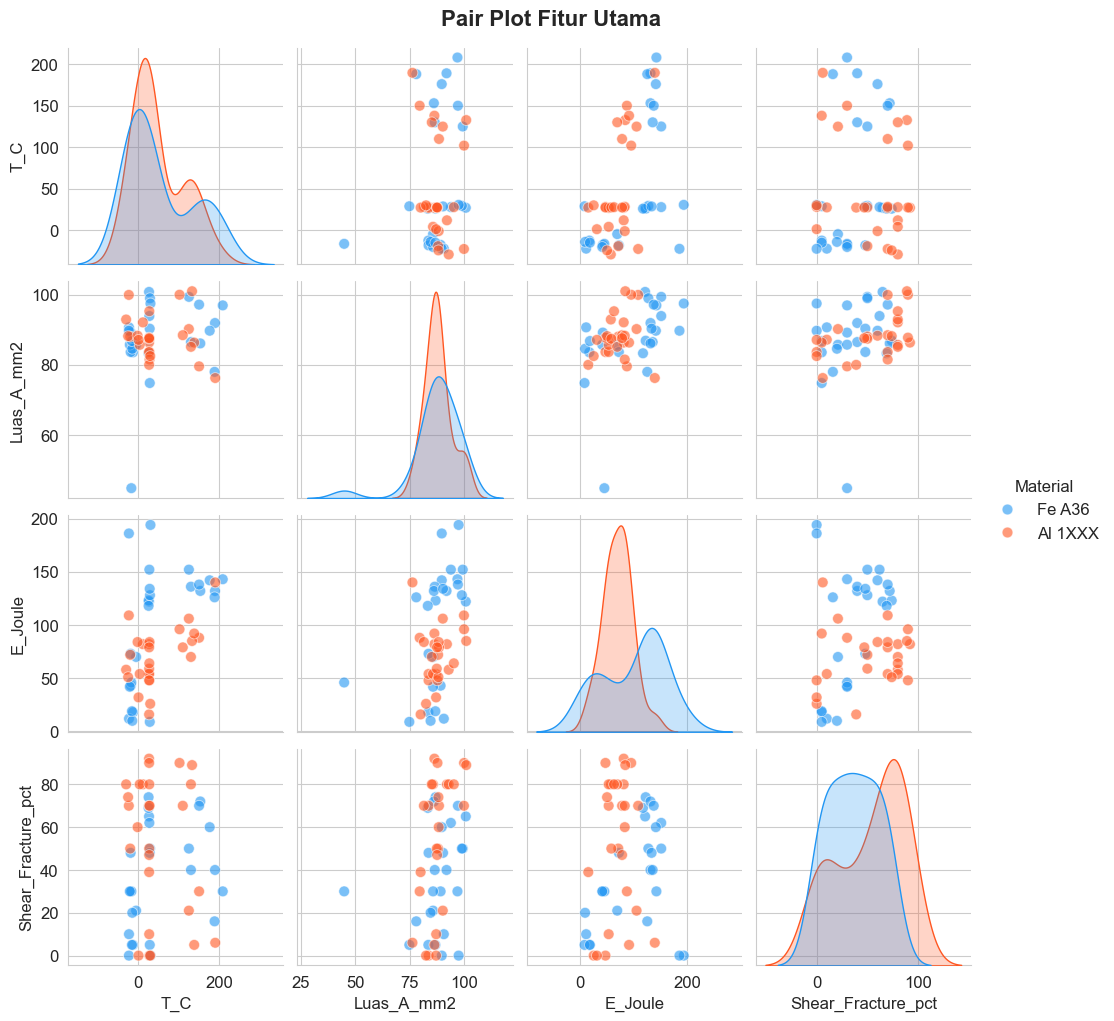

💾 Grafik disimpan: output/05_pair_plot.png


In [11]:
# Pair Plot fitur utama
pair_cols = ['T_C', 'Luas_A_mm2', 'E_Joule', 'Shear_Fracture_pct', 'Material']
g = sns.pairplot(df[pair_cols], hue='Material', palette=colors, 
                 diag_kind='kde', plot_kws={'alpha': 0.6, 's': 60, 'edgecolor': 'white'},
                 height=2.5)
g.figure.suptitle('Pair Plot Fitur Utama', y=1.02, fontsize=16, fontweight='bold')
plt.savefig('../outputs/figures/05_pair_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/05_pair_plot.png")

## 1.8 Ringkasan Temuan EDA

In [12]:
print("=" * 70)
print("📋 RINGKASAN TEMUAN EDA")
print("=" * 70)

print("""
🔍 TEMUAN UTAMA:

1. PENGARUH SUHU:
   • Fe A36: Energi impak meningkat signifikan dari suhu rendah ke suhu ruang.
     Pada suhu sangat rendah (<-15°C), energi turun drastis → transisi ulet-getas.
   • Al 1XXX: Energi impak lebih stabil terhadap perubahan suhu, namun 
     meningkat pada suhu tinggi.

2. PERBANDINGAN MATERIAL:
   • Fe A36 memiliki energi impak rata-rata LEBIH TINGGI dibanding Al 1XXX
   • Al 1XXX memiliki % Shear Fracture rata-rata LEBIH TINGGI → lebih ulet
   • Fe A36 lebih sensitif terhadap perubahan suhu (variasi lebih besar)

3. KORELASI:
   • Suhu vs Energi: korelasi positif pada kedua material
   • Material berpengaruh signifikan terhadap besaran energi impak
   • Dimensi spesimen (a, b, A) memiliki korelasi moderat dengan energi

4. FITUR ENGINEERING:
   • Ketangguhan (E/A) memberikan normalisasi yang lebih adil per luasan
   • Kategori suhu membantu segmentasi analisis
""")

📋 RINGKASAN TEMUAN EDA

🔍 TEMUAN UTAMA:

1. PENGARUH SUHU:
   • Fe A36: Energi impak meningkat signifikan dari suhu rendah ke suhu ruang.
     Pada suhu sangat rendah (<-15°C), energi turun drastis → transisi ulet-getas.
   • Al 1XXX: Energi impak lebih stabil terhadap perubahan suhu, namun 
     meningkat pada suhu tinggi.

2. PERBANDINGAN MATERIAL:
   • Fe A36 memiliki energi impak rata-rata LEBIH TINGGI dibanding Al 1XXX
   • Al 1XXX memiliki % Shear Fracture rata-rata LEBIH TINGGI → lebih ulet
   • Fe A36 lebih sensitif terhadap perubahan suhu (variasi lebih besar)

3. KORELASI:
   • Suhu vs Energi: korelasi positif pada kedua material
   • Material berpengaruh signifikan terhadap besaran energi impak
   • Dimensi spesimen (a, b, A) memiliki korelasi moderat dengan energi

4. FITUR ENGINEERING:
   • Ketangguhan (E/A) memberikan normalisasi yang lebih adil per luasan
   • Kategori suhu membantu segmentasi analisis



---
# PHASE 2: Machine Learning — Prediksi
---

## 2.1 Persiapan Data untuk ML

In [13]:
from sklearn.model_selection import LeaveOneOut, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

print("✅ Scikit-learn libraries berhasil diimport!")

✅ Scikit-learn libraries berhasil diimport!


In [14]:
# Persiapan Fitur dan Target
# Fitur: Material (one-hot), Suhu, a, b, Luas, Rasio_ab
features = ['Material_encoded', 'T_C', 'a_mm', 'b_mm', 'Luas_A_mm2', 'Rasio_ab']

X = df[features].values
y_energy = df['E_Joule'].values
y_shear = df['Shear_Fracture_pct'].values

print(f"📊 Fitur (X): {X.shape}")
print(f"🎯 Target Energi: {y_energy.shape}")
print(f"🎯 Target Shear: {y_shear.shape}")
print(f"\n📋 Fitur yang digunakan: {features}")

📊 Fitur (X): (53, 6)
🎯 Target Energi: (53,)
🎯 Target Shear: (53,)

📋 Fitur yang digunakan: ['Material_encoded', 'T_C', 'a_mm', 'b_mm', 'Luas_A_mm2', 'Rasio_ab']


## 2.2 Definisi Model

In [15]:
# Definisi Model-model yang akan dibandingkan
models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Ridge Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0))
    ]),
    'Polynomial Regression (deg=2)': Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', Ridge(alpha=1.0))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestRegressor(n_estimators=100, random_state=42, max_depth=5))
    ]),
    'SVR (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.1))
    ]),
    'Gradient Boosting': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42, 
                                            learning_rate=0.1))
    ]),
}

print(f"🧠 {len(models)} model didefinisikan:")
for i, name in enumerate(models.keys(), 1):
    print(f"   {i}. {name}")

🧠 6 model didefinisikan:
   1. Linear Regression
   2. Ridge Regression
   3. Polynomial Regression (deg=2)
   4. Random Forest
   5. SVR (RBF)
   6. Gradient Boosting


## 2.3 Training & Evaluasi — Target: Energi Impak (E, Joule)

In [16]:
# LOOCV untuk semua model — Target: Energi (E, Joule)
loo = LeaveOneOut()
results_energy = []

print("=" * 70)
print("🎯 TARGET: ENERGI IMPAK (E, Joule)")
print("=" * 70)
print(f"{'Model':<35} {'RMSE':>8} {'MAE':>8} {'R²':>8}  Waktu")
print("-" * 70)

for name, pipeline in models.items():
    start = time.time()
    
    # LOOCV predictions
    y_pred = cross_val_predict(pipeline, X, y_energy, cv=loo)
    
    # Metrics
    rmse = np.sqrt(mean_squared_error(y_energy, y_pred))
    mae = mean_absolute_error(y_energy, y_pred)
    r2 = r2_score(y_energy, y_pred)
    elapsed = time.time() - start
    
    results_energy.append({
        'Model': name,
        'Target': 'E (Joule)',
        'RMSE': round(rmse, 2),
        'MAE': round(mae, 2),
        'R2': round(r2, 4),
        'Waktu (s)': round(elapsed, 2)
    })
    
    print(f"{name:<35} {rmse:>8.2f} {mae:>8.2f} {r2:>8.4f}  {elapsed:.2f}s")

df_results_energy = pd.DataFrame(results_energy)
best_energy = df_results_energy.loc[df_results_energy['R2'].idxmax()]
print(f"\n🏆 Model Terbaik (Energi): {best_energy['Model']} | R² = {best_energy['R2']}")

🎯 TARGET: ENERGI IMPAK (E, Joule)
Model                                   RMSE      MAE       R²  Waktu
----------------------------------------------------------------------
Linear Regression                      40.33    29.92   0.2357  0.13s


Ridge Regression                       37.92    28.09   0.3245  0.15s


Polynomial Regression (deg=2)          49.53    31.40  -0.1526  0.17s


Random Forest                          40.30    29.46   0.2370  7.87s
SVR (RBF)                              32.81    25.44   0.4942  0.16s


Gradient Boosting                      47.10    33.46  -0.0426  3.38s

🏆 Model Terbaik (Energi): SVR (RBF) | R² = 0.4942


## 2.4 Training & Evaluasi — Target: Shear Fracture (%)

In [17]:
# LOOCV untuk semua model — Target: Shear Fracture (%)
results_shear = []

print("=" * 70)
print("🎯 TARGET: SHEAR FRACTURE (%)")
print("=" * 70)
print(f"{'Model':<35} {'RMSE':>8} {'MAE':>8} {'R²':>8}  Waktu")
print("-" * 70)

for name, pipeline in models.items():
    start = time.time()
    
    y_pred = cross_val_predict(pipeline, X, y_shear, cv=loo)
    
    rmse = np.sqrt(mean_squared_error(y_shear, y_pred))
    mae = mean_absolute_error(y_shear, y_pred)
    r2 = r2_score(y_shear, y_pred)
    elapsed = time.time() - start
    
    results_shear.append({
        'Model': name,
        'Target': 'Shear Fracture (%)',
        'RMSE': round(rmse, 2),
        'MAE': round(mae, 2),
        'R2': round(r2, 4),
        'Waktu (s)': round(elapsed, 2)
    })
    
    print(f"{name:<35} {rmse:>8.2f} {mae:>8.2f} {r2:>8.4f}  {elapsed:.2f}s")

df_results_shear = pd.DataFrame(results_shear)
best_shear = df_results_shear.loc[df_results_shear['R2'].idxmax()]
print(f"\n🏆 Model Terbaik (Shear): {best_shear['Model']} | R² = {best_shear['R2']}")

🎯 TARGET: SHEAR FRACTURE (%)
Model                                   RMSE      MAE       R²  Waktu
----------------------------------------------------------------------
Linear Regression                      32.87    24.98  -0.2446  0.17s


Ridge Regression                       29.69    24.03  -0.0155  0.16s


Polynomial Regression (deg=2)          36.15    27.67  -0.5052  0.21s


Random Forest                          29.95    24.84  -0.0332  8.01s
SVR (RBF)                              31.46    26.13  -0.1398  0.14s


Gradient Boosting                      34.58    26.86  -0.3773  3.22s

🏆 Model Terbaik (Shear): Ridge Regression | R² = -0.0155


## 2.5 Visualisasi Perbandingan Model

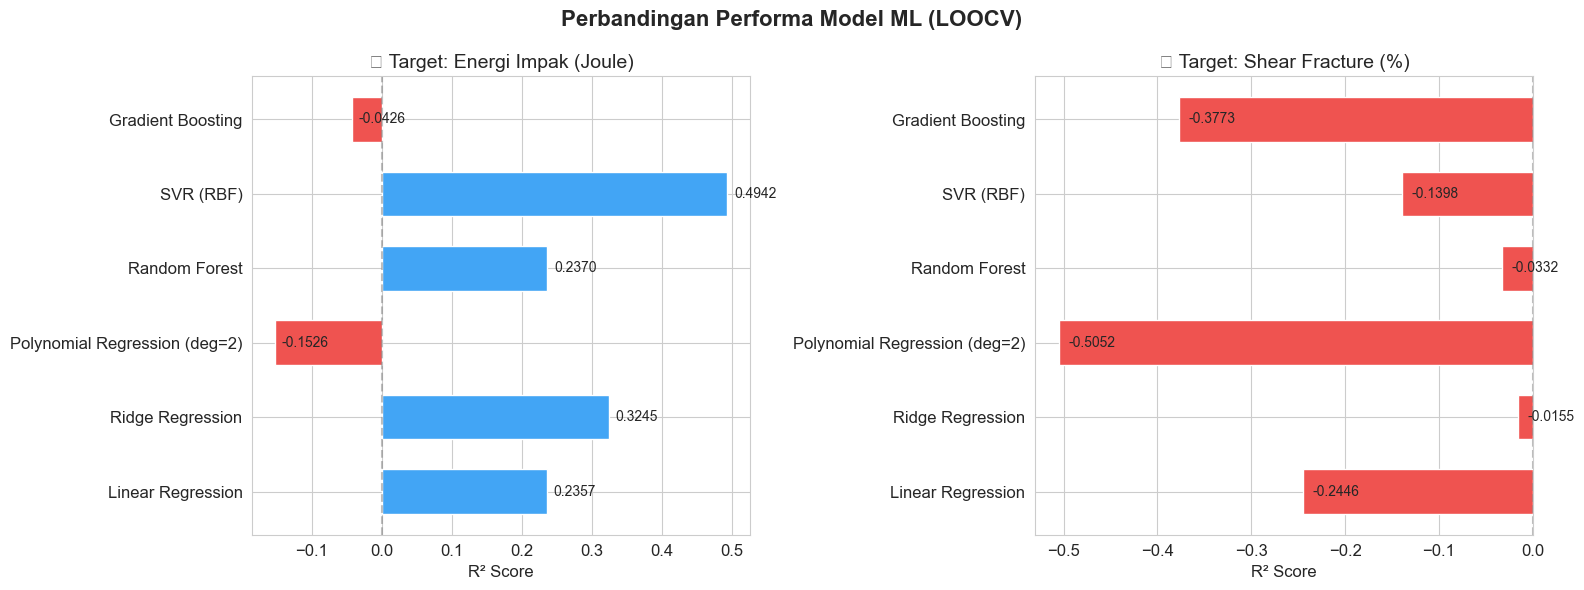

💾 Grafik disimpan: output/06_model_comparison.png


In [18]:
# Perbandingan Model (R² Score)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Perbandingan Performa Model ML (LOOCV)', fontsize=16, fontweight='bold')

# Energi
colors_bar = ['#42A5F5' if r2 > 0 else '#EF5350' for r2 in df_results_energy['R2']]
bars1 = axes[0].barh(df_results_energy['Model'], df_results_energy['R2'], color=colors_bar, 
                      edgecolor='white', height=0.6)
axes[0].set_xlabel('R² Score')
axes[0].set_title('🎯 Target: Energi Impak (Joule)')
axes[0].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
for bar, val in zip(bars1, df_results_energy['R2']):
    axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, 
                 f'{val:.4f}', va='center', fontsize=10)

# Shear Fracture
colors_bar2 = ['#66BB6A' if r2 > 0 else '#EF5350' for r2 in df_results_shear['R2']]
bars2 = axes[1].barh(df_results_shear['Model'], df_results_shear['R2'], color=colors_bar2,
                      edgecolor='white', height=0.6)
axes[1].set_xlabel('R² Score')
axes[1].set_title('🎯 Target: Shear Fracture (%)')
axes[1].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
for bar, val in zip(bars2, df_results_shear['R2']):
    axes[1].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('../outputs/figures/06_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/06_model_comparison.png")

## 2.6 Actual vs Predicted — Model Terbaik

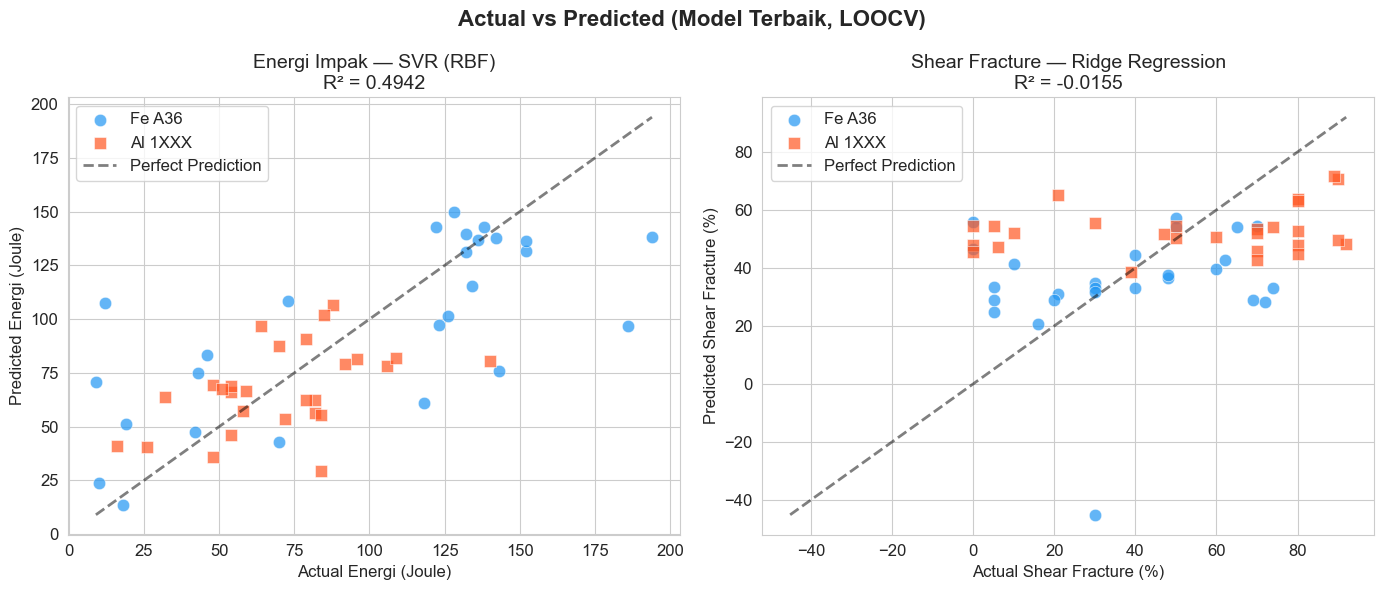

💾 Grafik disimpan: output/07_actual_vs_predicted.png


In [19]:
# Actual vs Predicted untuk model terbaik
best_energy_name = best_energy['Model']
best_shear_name = best_shear['Model']

# Re-predict dengan model terbaik
y_pred_energy_best = cross_val_predict(models[best_energy_name], X, y_energy, cv=loo)
y_pred_shear_best = cross_val_predict(models[best_shear_name], X, y_shear, cv=loo)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Actual vs Predicted (Model Terbaik, LOOCV)', fontsize=16, fontweight='bold')

# Energi
for material, color, marker in [('Fe A36', '#2196F3', 'o'), ('Al 1XXX', '#FF5722', 's')]:
    mask = df['Material'] == material
    axes[0].scatter(y_energy[mask], y_pred_energy_best[mask], c=color, marker=marker,
                    s=80, alpha=0.7, label=material, edgecolors='white', linewidth=0.5)

max_e = max(y_energy.max(), y_pred_energy_best.max())
min_e = min(y_energy.min(), y_pred_energy_best.min())
axes[0].plot([min_e, max_e], [min_e, max_e], 'k--', alpha=0.5, linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Energi (Joule)')
axes[0].set_ylabel('Predicted Energi (Joule)')
axes[0].set_title(f'Energi Impak — {best_energy_name}\nR² = {best_energy["R2"]:.4f}')
axes[0].legend()

# Shear Fracture
for material, color, marker in [('Fe A36', '#2196F3', 'o'), ('Al 1XXX', '#FF5722', 's')]:
    mask = df['Material'] == material
    axes[1].scatter(y_shear[mask], y_pred_shear_best[mask], c=color, marker=marker,
                    s=80, alpha=0.7, label=material, edgecolors='white', linewidth=0.5)

max_s = max(y_shear.max(), y_pred_shear_best.max())
min_s = min(y_shear.min(), y_pred_shear_best.min())
axes[1].plot([min_s, max_s], [min_s, max_s], 'k--', alpha=0.5, linewidth=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Shear Fracture (%)')
axes[1].set_ylabel('Predicted Shear Fracture (%)')
axes[1].set_title(f'Shear Fracture — {best_shear_name}\nR² = {best_shear["R2"]:.4f}')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/07_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/07_actual_vs_predicted.png")

## 2.7 Residual Analysis

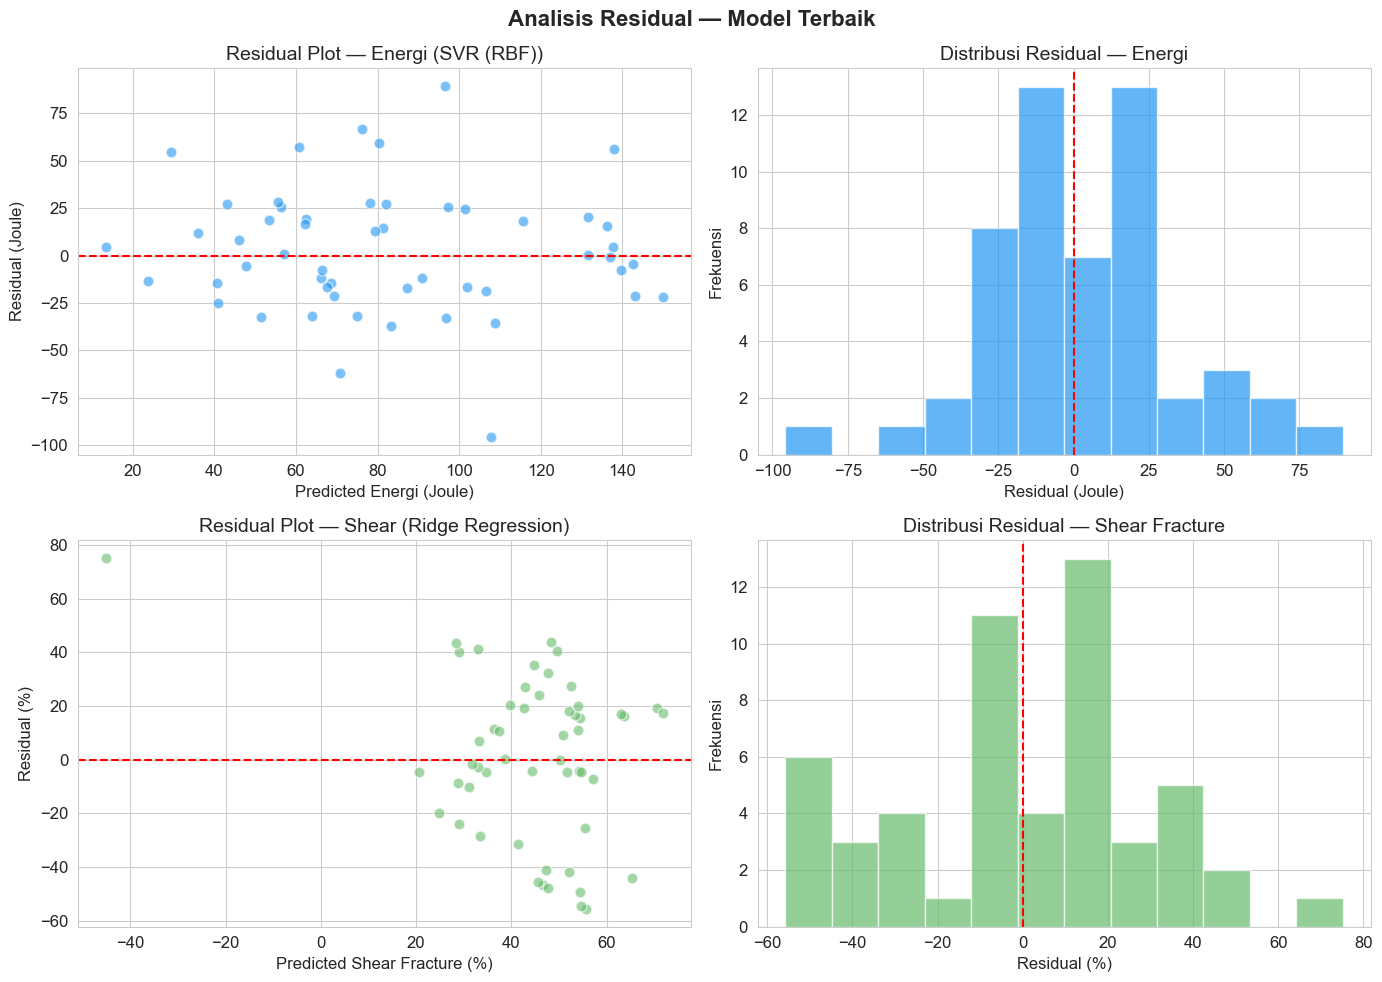

💾 Grafik disimpan: output/08_residual_analysis.png


In [20]:
# Residual Analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Analisis Residual — Model Terbaik', fontsize=16, fontweight='bold')

# Residual Energi
residual_e = y_energy - y_pred_energy_best
axes[0, 0].scatter(y_pred_energy_best, residual_e, c='#2196F3', alpha=0.6, s=60, edgecolors='white')
axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
axes[0, 0].set_xlabel('Predicted Energi (Joule)')
axes[0, 0].set_ylabel('Residual (Joule)')
axes[0, 0].set_title(f'Residual Plot — Energi ({best_energy_name})')

axes[0, 1].hist(residual_e, bins=12, color='#2196F3', edgecolor='white', alpha=0.7)
axes[0, 1].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
axes[0, 1].set_xlabel('Residual (Joule)')
axes[0, 1].set_ylabel('Frekuensi')
axes[0, 1].set_title('Distribusi Residual — Energi')

# Residual Shear Fracture
residual_s = y_shear - y_pred_shear_best
axes[1, 0].scatter(y_pred_shear_best, residual_s, c='#66BB6A', alpha=0.6, s=60, edgecolors='white')
axes[1, 0].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
axes[1, 0].set_xlabel('Predicted Shear Fracture (%)')
axes[1, 0].set_ylabel('Residual (%)')
axes[1, 0].set_title(f'Residual Plot — Shear ({best_shear_name})')

axes[1, 1].hist(residual_s, bins=12, color='#66BB6A', edgecolor='white', alpha=0.7)
axes[1, 1].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
axes[1, 1].set_xlabel('Residual (%)')
axes[1, 1].set_ylabel('Frekuensi')
axes[1, 1].set_title('Distribusi Residual — Shear Fracture')

plt.tight_layout()
plt.savefig('../outputs/figures/08_residual_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/08_residual_analysis.png")

## 2.8 Feature Importance (Random Forest)

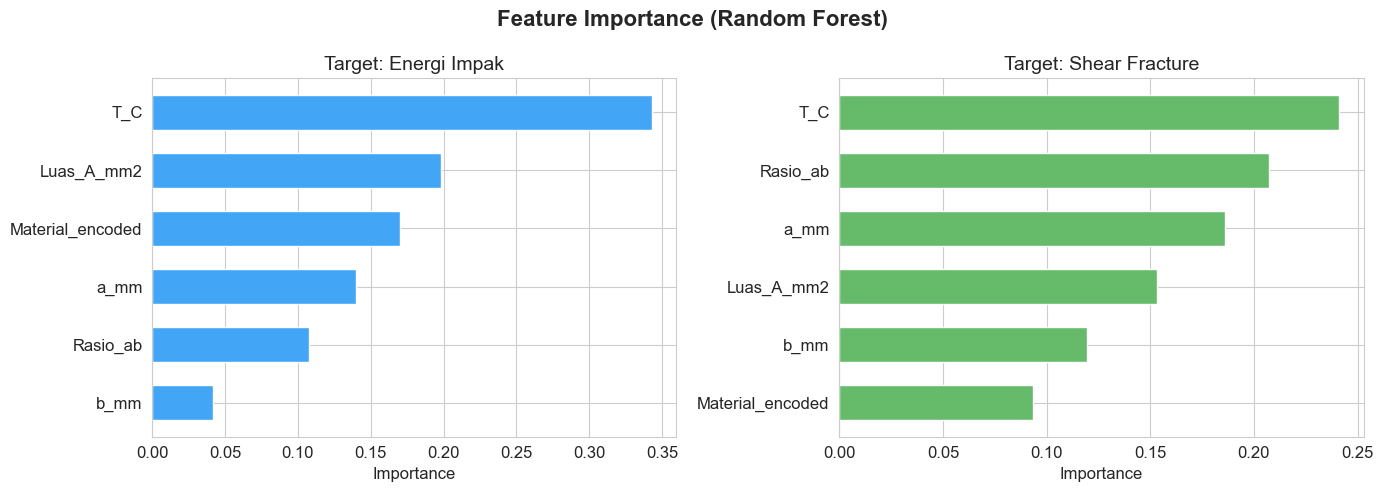

💾 Grafik disimpan: output/09_feature_importance.png


In [21]:
# Feature Importance dari Random Forest
rf_energy = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=5)
rf_energy.fit(X, y_energy)
importance_energy = rf_energy.feature_importances_

rf_shear = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=5)
rf_shear.fit(X, y_shear)
importance_shear = rf_shear.feature_importances_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Feature Importance (Random Forest)', fontsize=16, fontweight='bold')

# Importance Energi
idx_sorted_e = np.argsort(importance_energy)
axes[0].barh([features[i] for i in idx_sorted_e], importance_energy[idx_sorted_e],
             color='#42A5F5', edgecolor='white', height=0.6)
axes[0].set_xlabel('Importance')
axes[0].set_title('Target: Energi Impak')

# Importance Shear
idx_sorted_s = np.argsort(importance_shear)
axes[1].barh([features[i] for i in idx_sorted_s], importance_shear[idx_sorted_s],
             color='#66BB6A', edgecolor='white', height=0.6)
axes[1].set_xlabel('Importance')
axes[1].set_title('Target: Shear Fracture')

plt.tight_layout()
plt.savefig('../outputs/figures/09_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Grafik disimpan: output/09_feature_importance.png")

## 2.9 Export Data untuk Power BI (Phase 3 Preview)

In [22]:
# Export hasil prediksi ke CSV
import os
os.makedirs('../outputs/figures', exist_ok=True); os.makedirs('../outputs/tables', exist_ok=True)

# 1. Dataset + Prediksi
df_export = df.copy()
df_export['Prediksi_E_Joule'] = y_pred_energy_best
df_export['Prediksi_Shear_pct'] = y_pred_shear_best
df_export['Residual_E'] = residual_e
df_export['Residual_Shear'] = residual_s
df_export.to_csv('../outputs/tables/prediction_results.csv', index=False)
print("✅ output/prediction_results.csv")

# 2. Model Performance
df_perf = pd.concat([df_results_energy, df_results_shear], ignore_index=True)
df_perf.to_csv('../outputs/tables/model_performance.csv', index=False)
print("✅ output/model_performance.csv")

# 3. Feature Importance
df_importance = pd.DataFrame({
    'Feature': features,
    'Importance_Energy': importance_energy,
    'Importance_Shear': importance_shear
})
df_importance.to_csv('../outputs/tables/feature_importance.csv', index=False)
print("✅ output/feature_importance.csv")

print(f"\n📁 Semua file CSV siap diimport ke Power BI!")

✅ output/prediction_results.csv
✅ output/model_performance.csv
✅ output/feature_importance.csv

📁 Semua file CSV siap diimport ke Power BI!


## 2.10 Ringkasan Hasil ML

In [23]:
print("=" * 70)
print("📋 RINGKASAN HASIL MACHINE LEARNING")
print("=" * 70)

print(f"""
🎯 TARGET 1: Energi Impak (E, Joule)
   Model Terbaik : {best_energy['Model']}
   R² Score      : {best_energy['R2']:.4f}
   RMSE          : {best_energy['RMSE']:.2f} Joule
   MAE           : {best_energy['MAE']:.2f} Joule

🎯 TARGET 2: Shear Fracture (%)
   Model Terbaik : {best_shear['Model']}
   R² Score      : {best_shear['R2']:.4f}
   RMSE          : {best_shear['RMSE']:.2f} %
   MAE           : {best_shear['MAE']:.2f} %

📊 FITUR PALING PENTING (Random Forest):
   Energi  : {features[np.argmax(importance_energy)]} ({importance_energy.max():.4f})
   Shear   : {features[np.argmax(importance_shear)]} ({importance_shear.max():.4f})

📝 CATATAN:
   • Validasi menggunakan Leave-One-Out Cross Validation (LOOCV)
   • LOOCV dipilih karena dataset kecil (n={len(df)})
   • Semua model menggunakan StandardScaler untuk normalisasi fitur
   • File CSV sudah diekspor ke folder output/ untuk Power BI
""")

📋 RINGKASAN HASIL MACHINE LEARNING

🎯 TARGET 1: Energi Impak (E, Joule)
   Model Terbaik : SVR (RBF)
   R² Score      : 0.4942
   RMSE          : 32.81 Joule
   MAE           : 25.44 Joule

🎯 TARGET 2: Shear Fracture (%)
   Model Terbaik : Ridge Regression
   R² Score      : -0.0155
   RMSE          : 29.69 %
   MAE           : 24.03 %

📊 FITUR PALING PENTING (Random Forest):
   Energi  : T_C (0.3427)
   Shear   : T_C (0.2409)

📝 CATATAN:
   • Validasi menggunakan Leave-One-Out Cross Validation (LOOCV)
   • LOOCV dipilih karena dataset kecil (n=53)
   • Semua model menggunakan StandardScaler untuk normalisasi fitur
   • File CSV sudah diekspor ke folder output/ untuk Power BI



---
# PHASE 3: Hyperparameter Tuning — SVR (Model Terbaik)
---

Di Phase 2, SVR dijalankan dengan parameter manual. Sekarang kita cari
kombinasi parameter OPTIMAL menggunakan GridSearchCV + LOOCV.

In [24]:
from sklearn.model_selection import GridSearchCV
import joblib
import json

print("=" * 70)
print("🔧 PHASE 3: HYPERPARAMETER TUNING — SVR")
print("=" * 70)

# Pipeline SVR
svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# Grid parameter yang akan dicari
param_grid = {
    'svr__C':       [0.1, 1, 10, 50, 100, 500, 1000],
    'svr__gamma':   ['scale', 'auto', 0.001, 0.01, 0.1],
    'svr__epsilon': [0.01, 0.1, 0.5, 1.0, 5.0],
    'svr__kernel':  ['rbf', 'linear']
}

total_combinations = 7 * 5 * 5 * 2
print(f"📋 Total kombinasi parameter: {total_combinations} kombinasi")
print(f"📋 Metode validasi: LOOCV (n_splits = {len(df)})")
print(f"⏳ Sedang mencari parameter terbaik...\n")

🔧 PHASE 3: HYPERPARAMETER TUNING — SVR
📋 Total kombinasi parameter: 350 kombinasi
📋 Metode validasi: LOOCV (n_splits = 53)
⏳ Sedang mencari parameter terbaik...



In [25]:
# GridSearchCV — Target: Energi
loo2 = LeaveOneOut()

gs_energy = GridSearchCV(
    svr_pipeline,
    param_grid,
    cv=loo2,
    scoring='r2',
    n_jobs=-1,
    verbose=0
)
gs_energy.fit(X, y_energy)

print("🎯 TARGET: ENERGI IMPAK (E, Joule)")
print(f"   Best R²    : {gs_energy.best_score_:.4f}")
print(f"   Best params: {gs_energy.best_params_}")

🎯 TARGET: ENERGI IMPAK (E, Joule)
   Best R²    : nan
   Best params: {'svr__C': 0.1, 'svr__epsilon': 0.01, 'svr__gamma': 'scale', 'svr__kernel': 'rbf'}


In [26]:
# GridSearchCV — Target: Shear Fracture
gs_shear = GridSearchCV(
    svr_pipeline,
    param_grid,
    cv=loo2,
    scoring='r2',
    n_jobs=-1,
    verbose=0
)
gs_shear.fit(X, y_shear)

print("\n🎯 TARGET: SHEAR FRACTURE (%)")
print(f"   Best R²    : {gs_shear.best_score_:.4f}")
print(f"   Best params: {gs_shear.best_params_}")


🎯 TARGET: SHEAR FRACTURE (%)
   Best R²    : nan
   Best params: {'svr__C': 0.1, 'svr__epsilon': 0.01, 'svr__gamma': 'scale', 'svr__kernel': 'rbf'}


In [27]:
# Perbandingan: Sebelum vs Sesudah Tuning
r2_before_e = best_energy['R2']
r2_after_e  = gs_energy.best_score_
r2_before_s = best_shear['R2']
r2_after_s  = gs_shear.best_score_

print("\n" + "=" * 70)
print("📊 PERBANDINGAN SEBELUM vs SESUDAH TUNING")
print("=" * 70)
print(f"\n  Energi Impak:")
print(f"    Sebelum tuning (SVR default) : R² = {r2_before_e:.4f}")
status_e = '✅ Meningkat' if r2_after_e > r2_before_e else '⚠️ Sama'
print(f"    Sesudah tuning (SVR optimal) : R² = {r2_after_e:.4f}  {status_e}")
print(f"\n  Shear Fracture:")
print(f"    Sebelum tuning (Ridge)       : R² = {r2_before_s:.4f}")
status_s = '✅ Meningkat' if r2_after_s > r2_before_s else '⚠️ Sama'
print(f"    Sesudah tuning (SVR optimal) : R² = {r2_after_s:.4f}  {status_s}")


📊 PERBANDINGAN SEBELUM vs SESUDAH TUNING

  Energi Impak:
    Sebelum tuning (SVR default) : R² = 0.4942
    Sesudah tuning (SVR optimal) : R² = nan  ⚠️ Sama

  Shear Fracture:
    Sebelum tuning (Ridge)       : R² = -0.0155
    Sesudah tuning (SVR optimal) : R² = nan  ⚠️ Sama


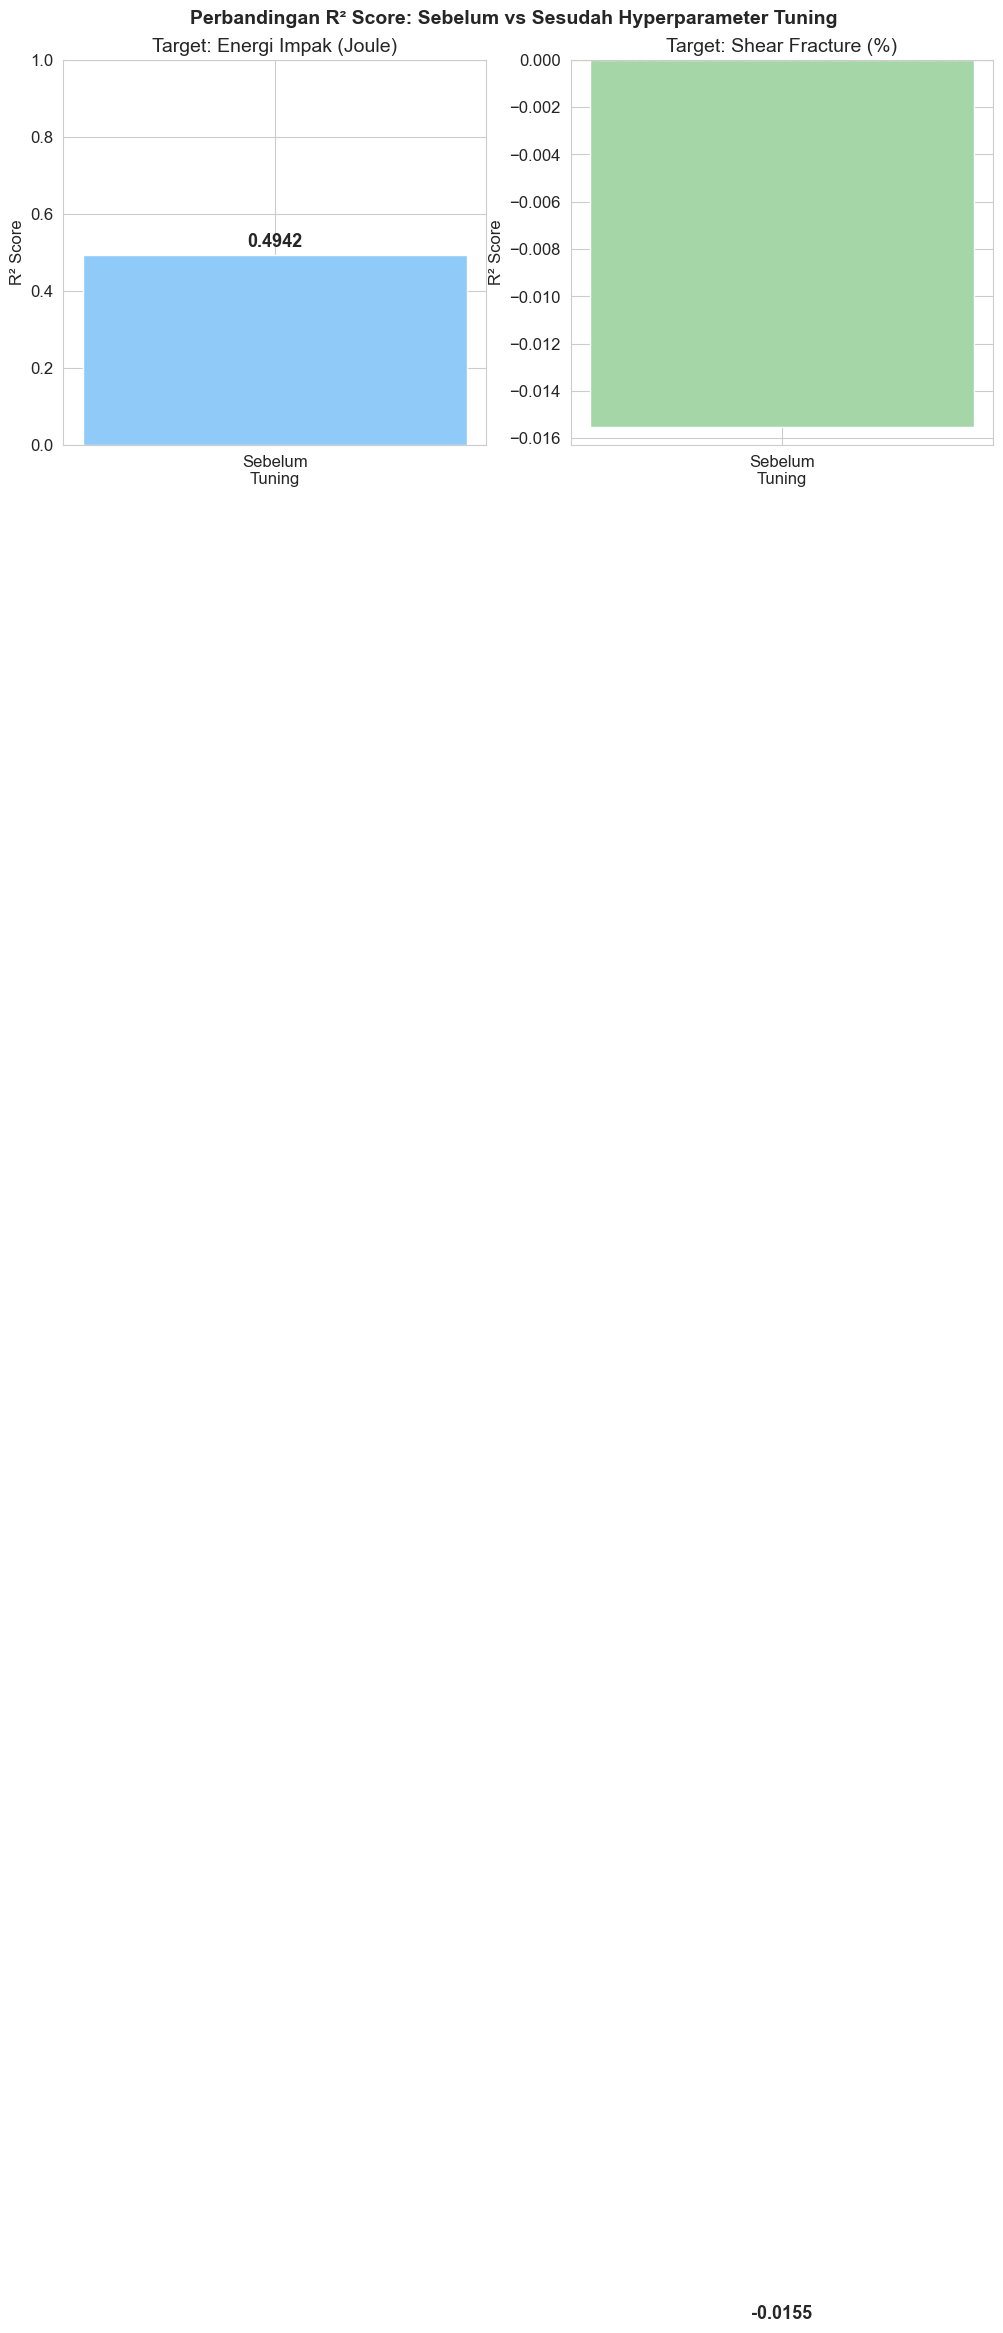

Grafik disimpan: output/10_tuning_comparison.png


In [28]:
# Visualisasi perbandingan Sebelum vs Sesudah Tuning
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Perbandingan R² Score: Sebelum vs Sesudah Hyperparameter Tuning',
             fontsize=14, fontweight='bold')

labels_compare = ['Sebelum\nTuning', 'Sesudah\nTuning']

# Energi
vals_e = [r2_before_e, r2_after_e]
colors_e = ['#90CAF9', '#1565C0']
bars = axes[0].bar(labels_compare, vals_e, color=colors_e, edgecolor='white', width=0.5)
axes[0].set_title('Target: Energi Impak (Joule)')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim(0, 1.0)
for bar, val in zip(bars, vals_e):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.4f}', ha='center', fontweight='bold', fontsize=13)

# Shear Fracture
vals_s = [r2_before_s, r2_after_s]
colors_s = ['#A5D6A7', '#2E7D32']
y_disp = [max(v, -0.6) for v in vals_s]
bars2 = axes[1].bar(labels_compare, y_disp, color=colors_s, edgecolor='white', width=0.5)
axes[1].set_title('Target: Shear Fracture (%)')
axes[1].set_ylabel('R² Score')
axes[1].axhline(y=0, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
for bar, val in zip(bars2, vals_s):
    y_pos = bar.get_height() + 0.02 if val >= 0 else bar.get_height() - 0.08
    axes[1].text(bar.get_x() + bar.get_width()/2, y_pos,
                 f'{val:.4f}', ha='center', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.savefig('../outputs/figures/10_tuning_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan: output/10_tuning_comparison.png")

---
# PHASE 4: Final Model Training
---

Setelah menemukan parameter optimal, latih model final menggunakan
seluruh dataset. Ini model yang akan digunakan untuk prediksi.

In [29]:
print("=" * 70)
print("PHASE 4: FINAL MODEL TRAINING")
print("=" * 70)

# Model final dengan parameter terbaik dari GridSearch
final_model_energy = gs_energy.best_estimator_
final_model_shear  = gs_shear.best_estimator_

# Fit ulang dengan seluruh data
final_model_energy.fit(X, y_energy)
final_model_shear.fit(X, y_shear)

# Evaluasi pada seluruh data (training score)
y_pred_final_e = final_model_energy.predict(X)
y_pred_final_s = final_model_shear.predict(X)

r2_train_e   = r2_score(y_energy, y_pred_final_e)
r2_train_s   = r2_score(y_shear,  y_pred_final_s)
rmse_train_e = np.sqrt(mean_squared_error(y_energy, y_pred_final_e))
rmse_train_s = np.sqrt(mean_squared_error(y_shear,  y_pred_final_s))

print(f"\nModel Energi (SVR Tuned) — Training Score:")
print(f"   R² = {r2_train_e:.4f}  |  RMSE = {rmse_train_e:.2f} Joule")
print(f"   Parameter: {gs_energy.best_params_}")
print(f"\nModel Shear (SVR Tuned) — Training Score:")
print(f"   R² = {r2_train_s:.4f}  |  RMSE = {rmse_train_s:.2f} %")
print(f"   Parameter: {gs_shear.best_params_}")
print(f"\nNote: Training score lebih tinggi dari CV score (wajar).")
print(f"Gunakan CV score (Phase 3) sebagai estimasi performa nyata.")

PHASE 4: FINAL MODEL TRAINING

Model Energi (SVR Tuned) — Training Score:
   R² = 0.0095  |  RMSE = 45.91 Joule
   Parameter: {'svr__C': 0.1, 'svr__epsilon': 0.01, 'svr__gamma': 'scale', 'svr__kernel': 'rbf'}

Model Shear (SVR Tuned) — Training Score:
   R² = -0.0039  |  RMSE = 29.52 %
   Parameter: {'svr__C': 0.1, 'svr__epsilon': 0.01, 'svr__gamma': 'scale', 'svr__kernel': 'rbf'}

Note: Training score lebih tinggi dari CV score (wajar).
Gunakan CV score (Phase 3) sebagai estimasi performa nyata.


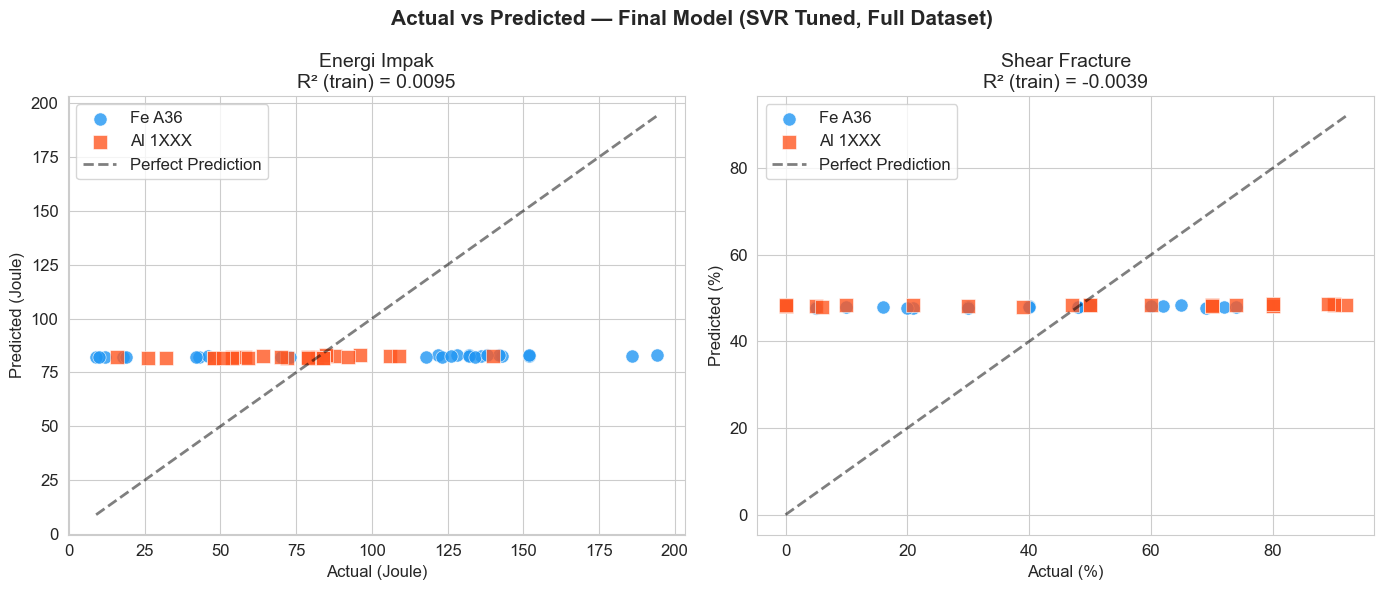

Grafik disimpan: output/11_final_actual_vs_predicted.png


In [30]:
# Visualisasi Actual vs Predicted — Final Model
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Actual vs Predicted — Final Model (SVR Tuned, Full Dataset)',
             fontsize=15, fontweight='bold')

for material, color, marker in [('Fe A36', '#2196F3', 'o'), ('Al 1XXX', '#FF5722', 's')]:
    mask = df['Material'] == material
    axes[0].scatter(y_energy[mask], y_pred_final_e[mask], c=color, marker=marker,
                    s=90, alpha=0.8, label=material, edgecolors='white', linewidth=0.5)
    axes[1].scatter(y_shear[mask],  y_pred_final_s[mask], c=color, marker=marker,
                    s=90, alpha=0.8, label=material, edgecolors='white', linewidth=0.5)

for ax, actual, pred, r2, unit, title in [
    (axes[0], y_energy, y_pred_final_e, r2_train_e, 'Joule', 'Energi Impak'),
    (axes[1], y_shear,  y_pred_final_s, r2_train_s, '%',     'Shear Fracture')
]:
    lo = min(actual.min(), pred.min())
    hi = max(actual.max(), pred.max())
    ax.plot([lo, hi], [lo, hi], 'k--', alpha=0.5, linewidth=2, label='Perfect Prediction')
    ax.set_xlabel(f'Actual ({unit})')
    ax.set_ylabel(f'Predicted ({unit})')
    ax.set_title(f'{title}\nR² (train) = {r2:.4f}')
    ax.legend()

plt.tight_layout()
plt.savefig('../outputs/figures/11_final_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan: output/11_final_actual_vs_predicted.png")

---
# PHASE 5: Model Saving & Fungsi Prediksi
---

In [31]:
print("=" * 70)
print("PHASE 5: SAVING MODEL & FUNGSI PREDIKSI")
print("=" * 70)

os.makedirs('../models', exist_ok=True)

# Simpan model
joblib.dump(final_model_energy, '../models/svr_energy_model.pkl')
joblib.dump(final_model_shear,  '../models/svr_shear_model.pkl')

# Simpan best params ke JSON
best_params_dict = {
    'energy': {k: str(v) for k, v in gs_energy.best_params_.items()},
    'shear':  {k: str(v) for k, v in gs_shear.best_params_.items()},
    'cv_r2_energy': round(gs_energy.best_score_, 4),
    'cv_r2_shear':  round(gs_shear.best_score_, 4),
    'features': features
}
with open('../models/best_params.json', 'w') as f:
    json.dump(best_params_dict, f, indent=2)

print("Model tersimpan:")
print("   model/svr_energy_model.pkl")
print("   model/svr_shear_model.pkl")
print("   model/best_params.json")

PHASE 5: SAVING MODEL & FUNGSI PREDIKSI
Model tersimpan:
   model/svr_energy_model.pkl
   model/svr_shear_model.pkl
   model/best_params.json


In [32]:
# Fungsi Prediksi
def prediksi_impak(material, suhu_C, a_mm, b_mm):
    """
    Prediksi Energi Impak dan Shear Fracture untuk spesimen baru.

    Parameters
    ----------
    material : str   -> 'Fe A36' atau 'Al 1XXX'
    suhu_C   : float -> Suhu pengujian (C)
    a_mm     : float -> Lebar takik spesimen (mm)
    b_mm     : float -> Tinggi spesimen (mm)
    """
    luas_A  = a_mm * b_mm
    rasio   = a_mm / b_mm
    mat_enc = 1 if material == 'Fe A36' else 0
    X_new   = np.array([[mat_enc, suhu_C, a_mm, b_mm, luas_A, rasio]])

    pred_e = max(0, final_model_energy.predict(X_new)[0])
    pred_s = max(0, min(100, final_model_shear.predict(X_new)[0]))

    return {
        'Material':            material,
        'Suhu (C)':            suhu_C,
        'Prediksi E (Joule)':  round(pred_e, 2),
        'Prediksi Shear (%)':  round(pred_s, 2),
        'Ketangguhan (kJ/m2)': round((pred_e / luas_A) * 1000, 2)
    }

# Demo prediksi kondisi baru
print("\nDEMO PREDIKSI — KONDISI BARU")
print("-" * 70)
demo_cases = [
    ('Fe A36',  -30, 9.0, 10.0),
    ('Fe A36',   25, 9.0, 10.0),
    ('Fe A36',  150, 9.0, 10.0),
    ('Al 1XXX', -30, 9.0, 10.0),
    ('Al 1XXX',  25, 9.0, 10.0),
    ('Al 1XXX', 150, 9.0, 10.0),
]
demo_results = []
for case in demo_cases:
    r = prediksi_impak(*case)
    demo_results.append(r)
    print(f"  {r['Material']:<10} | T={r['Suhu (C)']:>5}C "
          f"| E={r['Prediksi E (Joule)']:>7.2f} J "
          f"| Shear={r['Prediksi Shear (%)']:>6.2f}% "
          f"| Tangguh={r['Ketangguhan (kJ/m2)']:>7.2f} kJ/m2")
df_demo = pd.DataFrame(demo_results)


DEMO PREDIKSI — KONDISI BARU
----------------------------------------------------------------------
  Fe A36     | T=  -30C | E=  82.25 J | Shear= 47.96% | Tangguh= 913.92 kJ/m2
  Fe A36     | T=   25C | E=  82.43 J | Shear= 48.03% | Tangguh= 915.94 kJ/m2
  Fe A36     | T=  150C | E=  82.98 J | Shear= 48.16% | Tangguh= 922.04 kJ/m2
  Al 1XXX    | T=  -30C | E=  81.89 J | Shear= 48.47% | Tangguh= 909.91 kJ/m2
  Al 1XXX    | T=   25C | E=  81.98 J | Shear= 48.50% | Tangguh= 910.88 kJ/m2
  Al 1XXX    | T=  150C | E=  82.59 J | Shear= 48.34% | Tangguh= 917.64 kJ/m2


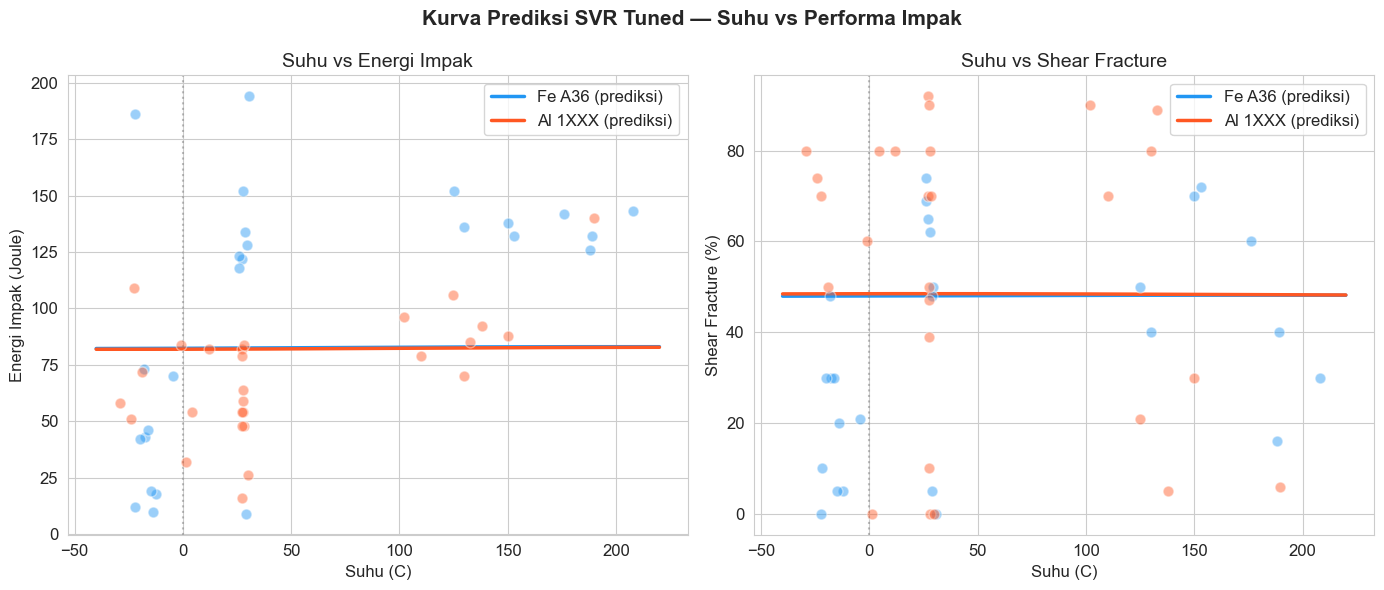

Grafik disimpan: output/12_prediction_curve.png


In [33]:
# Kurva prediksi vs suhu
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Kurva Prediksi SVR Tuned — Suhu vs Performa Impak',
             fontsize=15, fontweight='bold')

suhu_range   = np.linspace(-40, 220, 200)
a_ref, b_ref = 9.0, 10.0
luas_ref     = a_ref * b_ref
rasio_ref    = a_ref / b_ref
colors_mat   = {'Fe A36': '#2196F3', 'Al 1XXX': '#FF5722'}

for mat, enc in [('Fe A36', 1), ('Al 1XXX', 0)]:
    X_curve  = np.array([[enc, t, a_ref, b_ref, luas_ref, rasio_ref] for t in suhu_range])
    pred_e_c = np.clip(final_model_energy.predict(X_curve), 0, None)
    pred_s_c = np.clip(final_model_shear.predict(X_curve), 0, 100)

    axes[0].plot(suhu_range, pred_e_c, color=colors_mat[mat], linewidth=2.5, label=f'{mat} (prediksi)')
    axes[1].plot(suhu_range, pred_s_c, color=colors_mat[mat], linewidth=2.5, label=f'{mat} (prediksi)')

    subset = df[df['Material'] == mat]
    axes[0].scatter(subset['T_C'], subset['E_Joule'],
                    color=colors_mat[mat], s=60, alpha=0.45, edgecolors='white', zorder=5)
    axes[1].scatter(subset['T_C'], subset['Shear_Fracture_pct'],
                    color=colors_mat[mat], s=60, alpha=0.45, edgecolors='white', zorder=5)

for ax, ylabel, title in [
    (axes[0], 'Energi Impak (Joule)', 'Suhu vs Energi Impak'),
    (axes[1], 'Shear Fracture (%)',   'Suhu vs Shear Fracture')
]:
    ax.set_xlabel('Suhu (C)'); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.legend()
    ax.axvline(x=0, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('../outputs/figures/12_prediction_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan: output/12_prediction_curve.png")

---
# PHASE 6: Export Final untuk Power BI
---

In [34]:
print("=" * 70)
print("PHASE 6: EXPORT DATA FINAL UNTUK POWER BI")
print("=" * 70)

# 1. Dataset + prediksi final
df_final = df.copy()
df_final['Prediksi_E_Final']     = np.clip(final_model_energy.predict(X), 0, None).round(2)
df_final['Prediksi_Shear_Final'] = np.clip(final_model_shear.predict(X), 0, 100).round(2)
df_final['Residual_E']           = (df_final['E_Joule'] - df_final['Prediksi_E_Final']).round(2)
df_final['Residual_Shear']       = (df_final['Shear_Fracture_pct'] - df_final['Prediksi_Shear_Final']).round(2)
df_final['Error_pct_E']          = (abs(df_final['Residual_E']) / df_final['E_Joule'] * 100).round(2)
df_final.to_csv('../outputs/tables/final_prediction_results.csv', index=False)
print("Tersimpan: output/final_prediction_results.csv")

# 2. Model summary
loo3 = LeaveOneOut()
rmse_cv_e = np.sqrt(mean_squared_error(y_energy,
    cross_val_predict(final_model_energy, X, y_energy, cv=loo3)))
df_model_summary = pd.DataFrame({
    'Tahap':       ['Phase 2 - Default', 'Phase 3 - Tuned CV', 'Phase 4 - Final Train'],
    'Model':       ['SVR (RBF default)', 'SVR (RBF tuned)',    'SVR (RBF tuned)'],
    'R2_Energi':   [round(r2_before_e, 4), round(r2_after_e, 4), round(r2_train_e, 4)],
    'RMSE_Energi': [best_energy['RMSE'], round(rmse_cv_e, 2),    round(rmse_train_e, 2)],
    'R2_Shear':    [round(r2_before_s, 4), round(r2_after_s, 4), round(r2_train_s, 4)],
})
df_model_summary.to_csv('../outputs/tables/model_summary.csv', index=False)
print("Tersimpan: output/model_summary.csv")

# 3. Demo prediksi
df_demo.to_csv('../outputs/tables/demo_predictions.csv', index=False)
print("Tersimpan: output/demo_predictions.csv")

# 4. Feature importance (label lengkap)
feat_labels = {
    'Material_encoded': 'Jenis Material',
    'T_C':              'Suhu (C)',
    'a_mm':             'Lebar Takik a (mm)',
    'b_mm':             'Tinggi b (mm)',
    'Luas_A_mm2':       'Luas Penampang A (mm2)',
    'Rasio_ab':         'Rasio a/b'
}
df_imp_final = pd.DataFrame({
    'Feature':           features,
    'Feature_Label':     [feat_labels[f] for f in features],
    'Importance_Energy': importance_energy.round(4),
    'Importance_Shear':  importance_shear.round(4)
})
df_imp_final.to_csv('../outputs/tables/feature_importance_final.csv', index=False)
print("Tersimpan: output/feature_importance_final.csv")

print("""
=================================================================
  SEMUA PHASE SELESAI DIKERJAKAN!
=================================================================
  File Power BI:
  - output/final_prediction_results.csv   (data + prediksi final)
  - output/model_summary.csv          (ringkasan performa model)
  - output/model_performance.csv      (detail semua 6 model)
  - output/feature_importance_final.csv
  - output/demo_predictions.csv          (contoh prediksi baru)
  - model/svr_energy_model.pkl        (model tersimpan)

  12 Grafik PNG tersimpan di folder output/
=================================================================
""")

PHASE 6: EXPORT DATA FINAL UNTUK POWER BI
Tersimpan: output/final_prediction_results.csv
Tersimpan: output/model_summary.csv
Tersimpan: output/demo_predictions.csv
Tersimpan: output/feature_importance_final.csv

  SEMUA PHASE SELESAI DIKERJAKAN!
  File Power BI:
  - output/final_prediction_results.csv   (data + prediksi final)
  - output/model_summary.csv          (ringkasan performa model)
  - output/model_performance.csv      (detail semua 6 model)
  - output/feature_importance_final.csv
  - output/demo_predictions.csv          (contoh prediksi baru)
  - model/svr_energy_model.pkl        (model tersimpan)

  12 Grafik PNG tersimpan di folder output/

